# 03 · Modelos

Compara regresión lineal y regularizada contra el baseline de mediana con **las mismas particiones y reglas de calidad** (train ene-feb, validación mar). Los pipelines viven en `src/train.py`; el test final (jun-jul) no se toca.

In [1]:
from pathlib import Path
import sys, json
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
sys.path.insert(0, str(PROJECT_ROOT))
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
OUT = PROJECT_ROOT / "outputs"; FIG = PROJECT_ROOT / "reports" / "figures"
OUT.mkdir(exist_ok=True); FIG.mkdir(parents=True, exist_ok=True)
TRAIN_MONTHS = ("2026-01", "2026-02"); VAL_MONTHS = ("2026-03",)
import time
from src.data import load_clean_months
from src.train import make_baseline_median, linear_models, NUMERIC_COLS
from src.evaluate import regression_metrics

In [2]:
train = load_clean_months(TRAIN_MONTHS, PROJECT_ROOT/"data"); val = load_clean_months(VAL_MONTHS, PROJECT_ROOT/"data")
y_tr, y_va = train.duration_min.values, val.duration_min.values
print(f"train={len(train):,} val={len(val):,}")

train=6,964,100 val=3,862,063


In [3]:
results, preds, fitted = {}, {}, {}
base = make_baseline_median().fit(train[["PULocationID"]], y_tr)
preds["Baseline mediana"] = base.predict(val[["PULocationID"]])
results["Baseline mediana"] = {**regression_metrics(y_va, preds["Baseline mediana"]), "fit_seconds": 0.0}
for name, pipe in linear_models().items():
    t = time.time(); pipe.fit(train, y_tr); dt = time.time() - t
    preds[name] = pipe.predict(val); fitted[name] = pipe
    results[name] = {**regression_metrics(y_va, preds[name]), "fit_seconds": round(dt, 1)}
res = pd.DataFrame(results).T
res["MAE_gain_vs_baseline_%"] = (1 - res.MAE_minutes / res.loc["Baseline mediana","MAE_minutes"]) * 100
res

,MAE_minutes,RMSE_minutes,R2,fit_seconds,MAE_gain_vs_baseline_%
Baseline mediana,9.175125,14.789349,-0.057695,0.0,0.000000
LinearRegression,4.789693,7.892910,0.698743,3.5,47.796972
Ridge(alpha=10),4.789691,7.892905,0.698744,2.6,47.796993
Ridge + hora x finde (one-hot),4.713099,7.784880,0.706933,12.2,48.631774


## Lectura
- El baseline constante tiene R² ligeramente negativo: la mediana de ene-feb es una mala constante para marzo.
- Con solo información de inicio de viaje (zonas + hora), la regresión lineal ya reduce el MAE alrededor de 48 %, y casi toda la ganancia viene de `pair_mean`, la duración típica del par origen-destino.
- Ridge ≈ OLS: con millones de filas y pocas variables la regularización casi no cambia nada (no hay varianza que reducir). Se afinará `alpha` en la semana 12.
- El one-hot de hora × fin de semana aporta una mejora pequeña pero consistente: el efecto horario es no lineal.
- Un modelo lineal minimiza error cuadrático, no MAE; las colas largas (hasta 180 min) lo empujan hacia arriba. Esto motiva árboles/boosting en la semana 11.

In [4]:
best = res.drop("Baseline mediana").MAE_minutes.idxmin()
coef = pd.Series(fitted["Ridge(alpha=10)"].named_steps["model"].coef_, index=NUMERIC_COLS).sort_values()
print("Mejor lineal:", best); coef

Mejor lineal: Ridge + hora x finde (one-hot)


hour_cos             -2.003583
dow_cos              -1.073374
hour_sin             -1.033967
vendor_id            -0.777546
pickup_dayofweek     -0.502260
pu_zone_mean         -0.284015
pickup_hour          -0.214876
passenger_count      -0.033723
passenger_missing     0.003721
do_zone_mean          0.035666
same_zone             0.073503
pickup_is_weekend     0.176253
dow_sin               0.528269
pair_mean            11.460151
dtype: float32

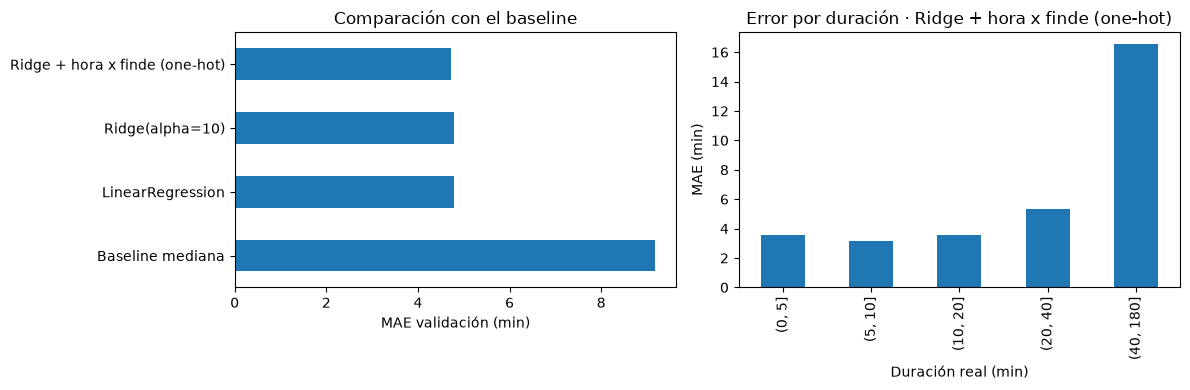

(0, 5]        3.575631
(5, 10]       3.170662
(10, 20]      3.567928
(20, 40]      5.363289
(40, 180]    16.524334
dtype: float64

In [5]:
err = np.abs(y_va - preds[best])
bins = pd.cut(y_va, [0,5,10,20,40,180])
by_dur = pd.Series(err).groupby(bins, observed=True).mean()
fig, axs = plt.subplots(1, 2, figsize=(12,4))
res["MAE_minutes"].plot.barh(ax=axs[0]); axs[0].set_xlabel("MAE validación (min)"); axs[0].set_title("Comparación con el baseline")
by_dur.plot.bar(ax=axs[1]); axs[1].set_xlabel("Duración real (min)"); axs[1].set_ylabel("MAE (min)"); axs[1].set_title(f"Error por duración · {best}")
plt.tight_layout(); plt.savefig(FIG/"09_linear_vs_baseline.png", dpi=150); plt.show()
by_dur

In [6]:
out = {"train_months": TRAIN_MONTHS, "validation_months": VAL_MONTHS, "train_rows": len(train),
       "validation_rows": len(val), "best_linear": best, "models": results}
(OUT/"linear_metrics.json").write_text(json.dumps(out, indent=2, default=int)); out["models"]

{'Baseline mediana': {'MAE_minutes': 9.175125379881168,
  'RMSE_minutes': 14.789349461494142,
  'R2': -0.05769515655400559,
  'fit_seconds': 0.0},
 'LinearRegression': {'MAE_minutes': 4.7896932738861135,
  'RMSE_minutes': 7.89290988056956,
  'R2': 0.698743336615494,
  'fit_seconds': 3.5},
 'Ridge(alpha=10)': {'MAE_minutes': 4.789691306052682,
  'RMSE_minutes': 7.892905094313823,
  'R2': 0.698743701979097,
  'fit_seconds': 2.6},
 'Ridge + hora x finde (one-hot)': {'MAE_minutes': 4.713099133472151,
  'RMSE_minutes': 7.784879895191986,
  'R2': 0.7069334804214531,
  'fit_seconds': 12.2}}